> **Clear all outputs before committing**: tiles, paths and slide
> identifiers must not end up in the repository.

# PROiFHESi sanity check (dry run)

Step-by-step check of the `finetuning/` pipeline on a few batches, before
launching `python -m validation.cross_val`:

1. **Setup** and **configuration** (real argument parser)
2. **Targets**: inventory, distributions, hierarchy constraints
3. **Model and data loaders**: build `PROiFHESi` once (H-optimus-1 + LoRA + head)
4. **Network**: trainable parameters, forward pass, hidden representations
5. **Data**: splits and leakage, one tile, augmentations, one batch
6. **Training**: one step, single-batch overfit, validation metrics, baseline
7. **Checkpoint**: save / reload round trip
8. **Trained checkpoint** (optional)
9. **Cleanup**

On CPU, H-optimus-1 (~1.1B parameters) is cast to
fp32: keep the batch small.

## 1. Setup

In [1]:
from __future__ import annotations

# General libraries
import shutil
import sys
import tempfile
from argparse import Namespace
from pathlib import Path

# Data libraries
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision.transforms as T
from PIL import Image

# Repository root on the path (first parent holding `finetuning/`)
REPO_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents) if (path / "finetuning").is_dir()
)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Project modules
from finetuning.arguments import AUGMENTATION_PROBABILITIES, get_arguments
from finetuning.dataloader import build_augmentations
from finetuning.metrics import INEQUALITY_CONSTRAINTS
from finetuning.model import PROiFHESi
from finetuning.network import RepresentationHook
from finetuning.predict import predict_image
from finetuning.utils import load_model_from_path
from validation.logger import configure_logging, timetracker

configure_logging(verbose=True)
tracker = timetracker(name="sanity check", verbose=True)

/cluster/CBIO/home/mblons/miniconda3/envs/cpath_py310/lib/python3.10/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.3.0) or chardet (6.0.0.post1)/charset_normalizer (3.4.1) doesn't match a supported version!
  warnings.warn(
/cluster/CBIO/home/mblons/miniconda3/envs/cpath_py310/lib/python3.10/site-packages/albumentations/__init__.py:24: UserWarning: A new version of Albumentations is available: 2.0.8 (you have 1.4.21). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


In [2]:
def denormalize(image: torch.Tensor, transform) -> torch.Tensor:
    """Undo the `Normalize` step of an encoder transform, for display."""
    normalize = next(
        step
        for step in getattr(transform, "transforms", [])
        if isinstance(step, T.Normalize)
    )
    mean = torch.as_tensor(normalize.mean).view(-1, 1, 1)
    std = torch.as_tensor(normalize.std).view(-1, 1, 1)
    return (image.float().cpu() * std + mean).clamp(0, 1)


def show_images(images, titles, n_columns=4, size=3.0):
    """Display images (HWC arrays or CHW tensors) in a grid."""
    n_rows = int(np.ceil(len(images) / n_columns))
    fig, axes = plt.subplots(
        n_rows,
        n_columns,
        figsize=(size * n_columns, size * n_rows),
        layout="constrained",
        squeeze=False,
    )
    for axis in axes.flat:
        axis.set_axis_off()
    for axis, image, title in zip(axes.flat, images, titles):
        if isinstance(image, torch.Tensor):
            image = image.permute(1, 2, 0).numpy()
        axis.imshow(image, aspect="equal")
        axis.set_title(title, fontsize=9)
    plt.show()


def count_parameters(module: torch.nn.Module) -> tuple[int, int]:
    """Return (trainable, total) parameter counts."""
    total = sum(parameter.numel() for parameter in module.parameters())
    trainable = sum(
        parameter.numel() for parameter in module.parameters() if parameter.requires_grad
    )
    return trainable, total

## 2. Configuration

Arguments go through the real parser (`get_arguments`): parser defaults <
YAML (`CONFIG_PATH`) < the list below, then the `configure_*` /
`validate_*` chain (encoder `feature_dim`, `eval_batch_size`, `metric_mode`,
...). Outputs go to a temporary `JOB_DIR`.

In [5]:
IMG_DIR = Path("/cluster/CBIO/data1/mblons/projects/PROiFHESi/data/ORION/20012026/CRC_TILE_SIGNATURE/tile_feat_20x_345px_0px_overlap/tile_0.5_mpp")  # holds tile images (*.jpeg)
INPUT_PATH = Path("/cluster/CBIO/data1/mblons/projects/PROiFHESi/data/ORION/20012026/CRC_TILE_SIGNATURE/tile_feat_20x_345px_0px_overlap/target/master_table_target_log1p_split_2026_09_22.csv")  # holds table img_path + test fold columns
TARGET_PATH = Path("/cluster/CBIO/data1/mblons/projects/PROiFHESi/data/ORION/20012026/CRC_TILE_SIGNATURE/tile_feat_20x_345px_0px_overlap/target/target_log1p.h5")  # holds the dataset signatures (N x F), and attributes
CONFIG_PATH = None  # optional YAML, e.g. Path("<configs/config_lora_variant.yaml>")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
JOB_DIR = Path(tempfile.mkdtemp(prefix="proifhesi_sanity_"))

cli = [
    "--img_dir", str(IMG_DIR),
    "--input_path", str(INPUT_PATH),
    "--target_path", str(TARGET_PATH),
    "--job_dir", str(JOB_DIR),
    "--device", DEVICE,
    "--test_fold", "0",
    "--batch_size", "4",
    "--epochs", "1",
    "--use_val",
    "--val_fraction", "0.2",
    "--num_workers", "0",
]
if CONFIG_PATH is not None:
    cli = ["--config", str(CONFIG_PATH), *cli]

args = get_arguments(known_args=cli, train=True)
pd.Series({key: str(value) for key, value in vars(args).items()}).to_frame("value")

,value
config,None
write_config,False
img_dir,/cluster/CBIO/data1/mblons/projects/PROiFHESi/...
img_format,jpeg
input_path,/cluster/CBIO/data1/mblons/projects/PROiFHESi/...
...,...
minimum_epochs,0
minimum_improvement,0.0
model_path,None
train,True


## 3. Targets

### 3.1 Inventory

Tiles on disk, tiles per fold in the input table, and per-target statistics
of the target h5 (check the normalisation: raw counts / densities vs
`log1p`, z-scores...).

In [6]:
tiles_on_disk = sorted(IMG_DIR.glob(f"*.{args.img_format}"))
print(f"{len(tiles_on_disk)} *.{args.img_format} tiles in img_dir")

input_table = pd.read_csv(INPUT_PATH)
print(input_table["test"].value_counts().sort_index().rename("tiles per fold"))

with h5py.File(TARGET_PATH, "r") as file:
    signature = file["signature"][:]
    target_names = [
        name.decode() if isinstance(name, bytes) else str(name)
        for name in file["signature"].attrs["feat"]
    ]

signature_table = pd.DataFrame(signature, columns=target_names)
target_stats = signature_table.describe().T
target_stats["zero_fraction"] = (signature == 0).mean(axis=0)
target_stats

644239 *.jpeg tiles in img_dir
test
0.0    157349
1.0     95177
2.0    132497
3.0    137985
4.0    117916
Name: tiles per fold, dtype: int64


,count,mean,std,min,25%,50%,75%,max,zero_fraction
cells,640924.0,3.938426,0.955500,0.693147,3.367296,4.143135,4.672829,6.188264,0.000000
CD45+,640924.0,2.749975,1.421267,0.000000,1.791759,2.833213,3.871201,5.940171,0.073581
CD68+,640924.0,1.420318,1.185573,0.000000,0.000000,1.386294,2.302585,5.627621,0.260165
CD163+,640924.0,1.502713,1.179204,0.000000,0.000000,1.386294,2.397895,5.416100,0.251167
CD3e+,640924.0,2.134867,1.419535,0.000000,1.098612,2.079442,3.218876,5.828946,0.152024
CD8a+,640924.0,1.016462,1.193865,0.000000,0.000000,0.693147,1.791759,5.739793,0.450411
CD45R0+,640924.0,1.552239,1.553166,0.000000,0.000000,1.098612,2.639057,5.926926,0.340653
CD20+,640924.0,0.792610,1.207122,0.000000,0.000000,0.000000,1.386294,5.872118,0.572058
CD4+,640924.0,1.994527,1.412225,0.000000,0.693147,1.945910,3.044522,5.828946,0.176636
FOXP3+,640924.0,0.747764,1.020712,0.000000,0.000000,0.000000,1.386294,5.774552,0.529713


### 3.2 Distributions and correlations

Heavy tails or near-constant targets explain low per-target Pearson / R².
Strong correlations show which markers the head can share.

In [ ]:
# denormalize the logp1

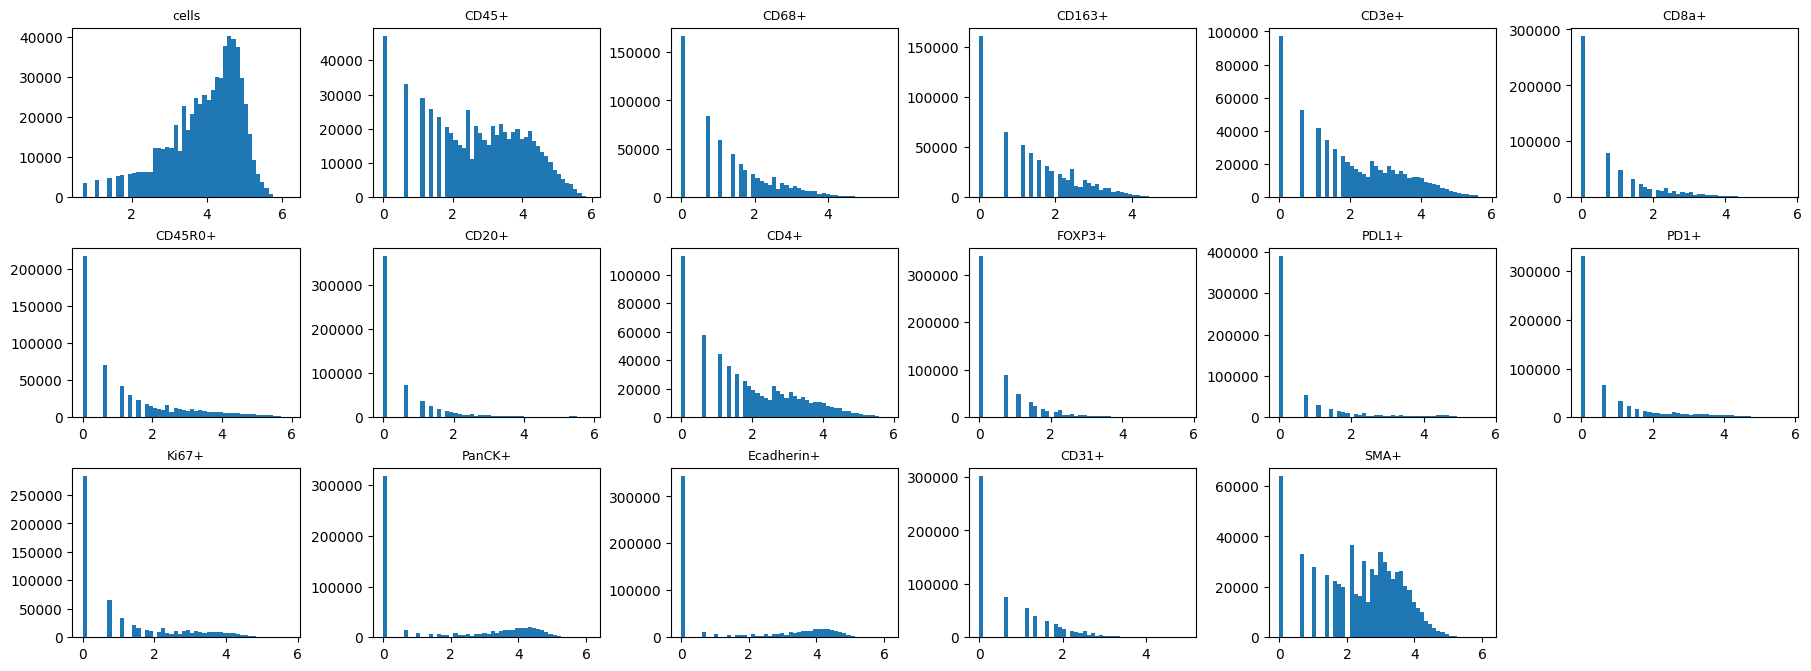

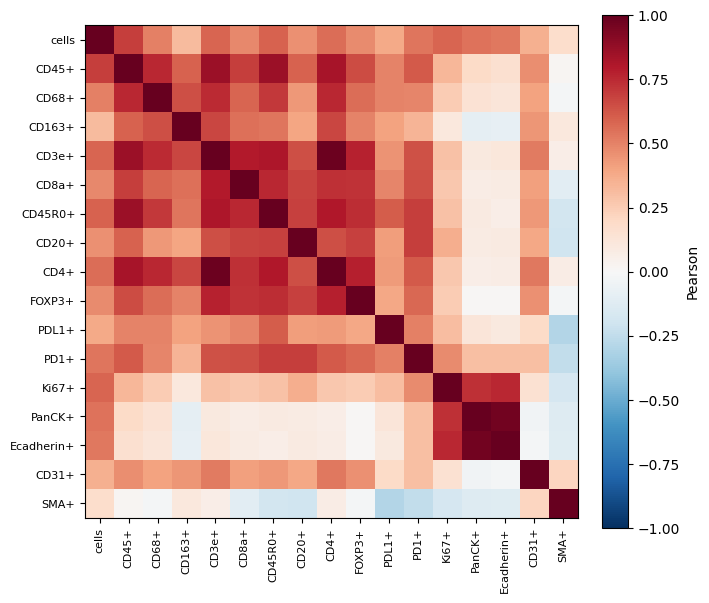

In [7]:
n_columns = 6
n_rows = int(np.ceil(len(target_names) / n_columns))
fig, axes = plt.subplots(
    n_rows,
    n_columns,
    figsize=(3 * n_columns, 2.2 * n_rows),
    layout="constrained",
    squeeze=False,
)
for axis in axes.flat:
    axis.set_axis_off()
for axis, target_name in zip(axes.flat, target_names):
    axis.set_axis_on()
    axis.hist(signature_table[target_name], bins=50)
    axis.set_title(target_name, fontsize=9)
plt.show()

fig, axis = plt.subplots(figsize=(7, 6), layout="constrained")
image = axis.imshow(signature_table.corr(), vmin=-1, vmax=1, cmap="RdBu_r")
axis.set_xticks(range(len(target_names)), target_names, rotation=90, fontsize=8)
axis.set_yticks(range(len(target_names)), target_names, fontsize=8)
fig.colorbar(image, ax=axis, label="Pearson")
plt.show()

### 3.3 Hierarchy constraints on the ground truth

`criterion=hierarchy` penalises predictions violating `A <= B`
(`INEQUALITY_CONSTRAINTS`). The measured targets should (almost) never
violate them; frequent violations mean the constraint or the target
normalisation does not fit the data.

In [8]:
violations = []
for marker_a, marker_b in dict.fromkeys(INEQUALITY_CONSTRAINTS):
    if marker_a in signature_table and marker_b in signature_table:
        violations.append(
            {
                "constraint": f"{marker_a} <= {marker_b}",
                "violation_fraction": float(
                    (signature_table[marker_a] > signature_table[marker_b]).mean()
                ),
            }
        )
pd.DataFrame(violations).sort_values("violation_fraction", ascending=False)

,constraint,violation_fraction
18,CD163+ <= CD68+,0.470177
27,CD45R0+ <= CD3e+,0.107690
29,PD1+ <= CD3e+,0.086115
31,Ecadherin+ <= PanCK+,0.083169
19,CD163+ <= CD45+,0.066442
30,PD1+ <= CD45+,0.043960
22,CD4+ <= CD3e+,0.041762
15,CD3e+ <= CD45+,0.027832
23,CD4+ <= CD45+,0.024251
17,CD68+ <= CD45+,0.017520


## 4. Model and data loaders

`PROiFHESi(args, with_data=True)` builds the network (HISTONAUT encoder +
LoRA + `PredictionHead`), the `DatasetHandler` and the loaders. Built once
and reused below.

In [9]:
tracker.tic()
model = PROiFHESi(args, with_data=True)
tracker.toc()

handler = model.dataset_handler
print(f"precision      = {model.network.precision}")
print(f"targets ({len(model.target_names)}) = {model.target_names}")
print(f"train batches  = {len(model.train_loader)}")
print(f"val batches    = {len(model.val_loader) if model.val_loader else 'no validation'}")

2026-11-25 18:46:41 | INFO     | HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
2026-11-25 18:46:41 | INFO     | HTTP Request: HEAD https://huggingface.co/bioptimus/H-optimus-1/resolve/main/config.json "HTTP/1.1 200 OK"
2026-11-25 18:47:13 | INFO     | Loading pretrained weights from Hugging Face hub (bioptimus/H-optimus-1)
2026-11-25 18:47:13 | INFO     | HTTP Request: HEAD https://huggingface.co/bioptimus/H-optimus-1/resolve/main/model.safetensors "HTTP/1.1 302 Found"
2026-11-25 18:47:13 | INFO     | [bioptimus/H-optimus-1] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.
2026-11-25 18:47:24 | INFO     | Trainable parameters (LoRA + head): 1992209 / 1136766481 (0.1753%).
2026-11-25 18:48:01 | INFO     | Constructed training dataset with 483575 tiles.
2026-11-25 18:48:37 | INFO     | Constructed training dataset with 483575 tiles.
2026-11-25 18:49:18 | INFO     | Constructed evaluation datas

precision      = {'backbone': torch.float32, 'lora': torch.float32, 'head': torch.float32}
targets (17) = ['cells', 'CD45+', 'CD68+', 'CD163+', 'CD3e+', 'CD8a+', 'CD45R0+', 'CD20+', 'CD4+', 'FOXP3+', 'PDL1+', 'PD1+', 'Ki67+', 'PanCK+', 'Ecadherin+', 'CD31+', 'SMA+']
train batches  = 96715
val batches    = 24179


## 5. Network

### 5.1 Trainable parameters

With LoRA, only `lora_*` adapters and the head must be trainable; the
backbone weights stay frozen in their native precision.

In [10]:
parameter_table = pd.DataFrame(
    [
        ("backbone", *count_parameters(model.network.backbone)),
        ("head", *count_parameters(model.network.head)),
        ("total", *count_parameters(model.network)),
    ],
    columns=["part", "trainable", "total"],
).set_index("part")
parameter_table["trainable_%"] = 100 * parameter_table["trainable"] / parameter_table["total"]
display(parameter_table)

trainable_names = [
    name for name, parameter in model.network.named_parameters() if parameter.requires_grad
]
unexpected = [
    name for name in trainable_names if "lora_" not in name and not name.startswith("head.")
]
print(f"{len(trainable_names)} trainable tensors, unexpected: {unexpected}")

lora_targets = [
    name
    for name, _ in model.network.backbone.named_modules()
    if name.split(".")[-1] in args.lora_target
]
print(f"{len(lora_targets)} modules targeted by LoRA ({args.lora_target})")

model.network.log_summary(part="head")

,trainable,total,trainable_%
part,,,
backbone,1966080,1136740352,0.172958
head,26129,26129,100.000000
total,1992209,1136766481,0.175252


2026-11-25 18:51:14 | INFO     | =================================================================
Layer (type:depth-idx)                   Param #
PredictionHead                           --
├─Sequential: 1-1                        --
│    └─Linear: 2-1                       26,129
Total params: 26,129
Trainable params: 26,129
Non-trainable params: 0


82 trainable tensors, unexpected: []
40 modules targeted by LoRA (['qkv'])


Layer (type:depth-idx)                   Param #
PredictionHead                           --
├─Sequential: 1-1                        --
│    └─Linear: 2-1                       26,129
Total params: 26,129
Trainable params: 26,129
Non-trainable params: 0

### 5.2 Forward pass

Prediction (B, `output_dim`) and backbone embedding (B, `feature_dim`) on
one validation batch, in fp32.

In [ ]:
evaluation_loader = model.val_loader or handler.get_loader(training=False)
evaluation_batch = next(iter(evaluation_loader))

forward_result = model.predict_batch(evaluation_batch, return_embeddings=True)
print(f"image      {tuple(evaluation_batch['image'].shape)} {evaluation_batch['image'].dtype}")
print(f"prediction {forward_result['prediction'].shape} {forward_result['prediction'].dtype}")
print(f"embedding  {forward_result['embedding'].shape} {forward_result['embedding'].dtype}")

assert forward_result["prediction"].shape[1] == args.output_dim
assert forward_result["embedding"].shape[1] == args.feature_dim
assert np.isfinite(forward_result["prediction"]).all()

### 5.3 Hidden representations

`RepresentationHook` records the hidden blocks of the head
(`head.network.<i>`): embedding -> hidden widths (`width_fe`) -> signature.

In [11]:
hidden_layers = model.network.hidden_layer_names()
print(f"hidden layers: {hidden_layers or 'none (width_fe is empty)'}")

if hidden_layers:
    with RepresentationHook(model.network, hidden_layers) as hook:
        model.predict_batch(evaluation_batch)
    for name, representation in hook.representations.items():
        print(f"{name:20s} {tuple(representation.shape)}")

hidden layers: none (width_fe is empty)


## 6. Data

### 6.1 Splits and leakage

Train / validation indices come from one seeded `ShuffleSplit` of the
training folds; test tiles are the `test_fold` tiles. Train, validation and
test must not share tiles.

In [12]:
train_indices = list(handler.train_sampler.indices)
val_indices = list(handler.val_sampler.indices) if handler.val_sampler else []
train_paths = {handler.dataset_train.files[index] for index in train_indices}
val_paths = {handler.dataset_train.files[index] for index in val_indices}
test_paths = set(handler.dataset_test.files)

print(f"train={len(train_paths)} | validation={len(val_paths)} | test={len(test_paths)}")
assert not train_paths & val_paths, "train / validation overlap"
assert not (train_paths | val_paths) & test_paths, "train / test overlap"

train=386860 | validation=96715 | test=157349


The validation split is **tile-wise**: neighbouring tiles of
the same slide fall in train and validation, which inflates validation
metrics. Adapt `slide_from_path` to the tile naming scheme to measure it.

In [ ]:
def slide_from_path(path) -> str:
    """Slide identifier of a tile named `<slide>_<level>_<x>_<y>_<w>_<h>.<ext>` (preprocessing/tile_extraction.py)."""
    return Path(path).stem.rsplit("_", 5)[0]


train_slides = {slide_from_path(path) for path in train_paths}
val_slides = {slide_from_path(path) for path in val_paths}
test_slides = {slide_from_path(path) for path in test_paths}
print(f"slides: train={len(train_slides)} | validation={len(val_slides)} | test={len(test_slides)}")
print(f"validation slides also in train: {len(val_slides & train_slides)} / {len(val_slides)}")
print(f"test slides also in train: {len(test_slides & train_slides)} / {len(test_slides)}")

### 6.2 One tile

Raw tile, encoder input (de-normalised for display) and its signature,
from the validation dataset (no augmentation).

raw tile     (224, 224, 3) uint8
input tensor (3, 224, 224) torch.float32


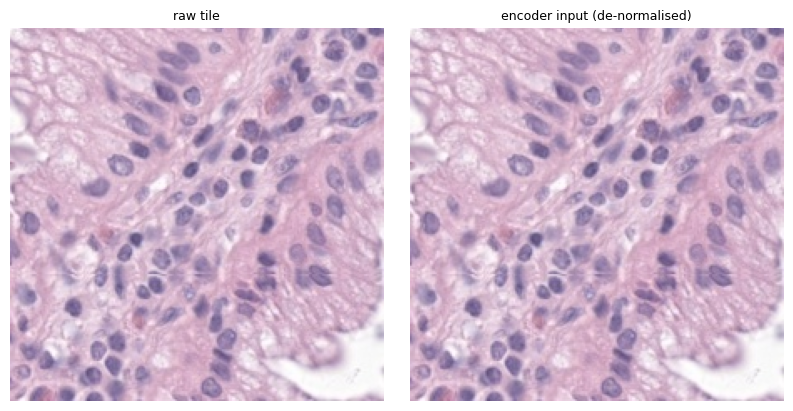

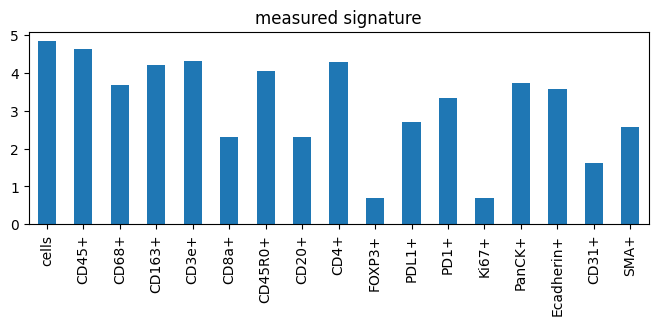

In [15]:
item = handler.dataset_val[val_indices[0]] if val_indices else handler.dataset_test[0]
tile_path = Path(item["path"])
raw_tile = np.asarray(Image.open(tile_path).convert("RGB"))

print(f"raw tile     {raw_tile.shape} {raw_tile.dtype}")
print(f"input tensor {tuple(item['image'].shape)} {item['image'].dtype}")
show_images(
    [raw_tile, denormalize(item["image"], model.network.transform)],
    ["raw tile", "encoder input (de-normalised)"],
    n_columns=2,
    size=4,
)

pd.Series(np.asarray(item["target"]), index=model.target_names).plot.bar(
    figsize=(8, 2.5),
    title="measured signature",
)
plt.show()

### 6.3 Augmentations

Each augmentation applied alone (probability forced to 1) on the raw tile,
with the configured parameters of `build_augmentations`.

{'p_hflip': 0.5, 'p_vflip': 0.5, 'p_rotate90': 0.5, 'p_brightness_contrast': 0.5, 'p_blur': 0.1, 'p_noise': 0.1}


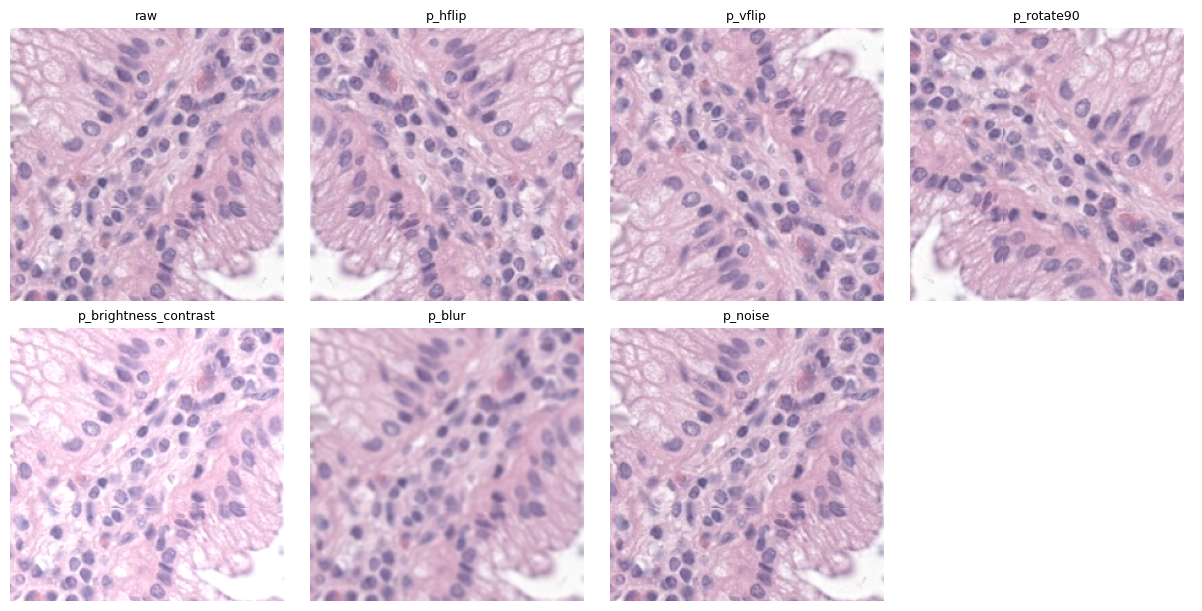

In [18]:
augmented_tiles = [raw_tile]
augmentation_titles = ["raw"]
for probability_name in AUGMENTATION_PROBABILITIES:
    single_augmentation_args = Namespace(
        **{
            **vars(args),
            **{name: 0.0 for name in AUGMENTATION_PROBABILITIES},
            probability_name: 1.0,
            "augment": True,
        }
    )
    augmentation = build_augmentations(single_augmentation_args, training=True)
    augmented_tiles.append(augmentation(image=raw_tile)["image"])
    augmentation_titles.append(probability_name)

print({name: getattr(args, name) for name in AUGMENTATION_PROBABILITIES})
show_images(augmented_tiles, augmentation_titles, n_columns=4)

### 6.4 One training batch

Augmented training batch as the network sees it (de-normalised).

image  (4, 3, 224, 224) torch.float32
target (4, 17) torch.float32


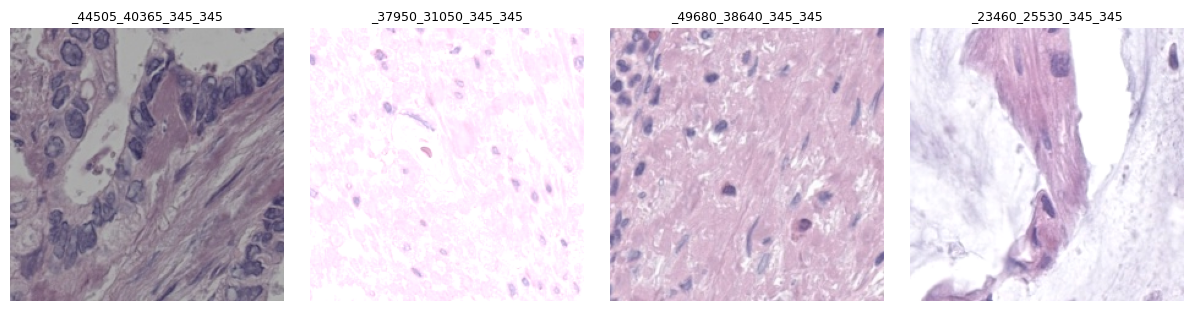

In [20]:
train_batch = next(iter(model.train_loader))
print(f"image  {tuple(train_batch['image'].shape)} {train_batch['image'].dtype}")
print(f"target {tuple(train_batch['target'].shape)} {train_batch['target'].dtype}")
show_images(
    [denormalize(image, model.network.transform) for image in train_batch["image"]],
    [Path(path).stem[-20:] for path in train_batch["path"]],
)

## 7. Training

### 7.1 One optimisation step

The loss must be finite, trainable tensors must move and frozen backbone
weights must not. Note: LoRA `B` matrices start at zero, so `lora_A` may
only move through weight decay at the first step.

In [ ]:
named_parameters = dict(model.network.named_parameters())
frozen_name = next(name for name, parameter in named_parameters.items() if not parameter.requires_grad)
frozen_before = named_parameters[frozen_name].detach().clone()
trainable_before = {
    name: parameter.detach().clone()
    for name, parameter in named_parameters.items()
    if parameter.requires_grad
}

step_loss = model.train_batch(train_batch)

moved = [
    name
    for name, before in trainable_before.items()
    if not torch.equal(before, named_parameters[name].detach())
]
print(f"loss = {step_loss:.4f} ({args.criterion})")
print(f"trainable tensors moved: {len(moved)} / {len(trainable_before)}")
print(f"frozen tensor unchanged ({frozen_name}): {torch.equal(frozen_before, named_parameters[frozen_name].detach())}")
assert np.isfinite(step_loss)
assert torch.equal(frozen_before, named_parameters[frozen_name].detach())

### 7.2 Overfit one batch

Repeating the same batch, the training loss should drop clearly. If it does
not, check the learning rate, the loss / target scale and the trainable
parameters before launching a full run.

In [ ]:
N_OVERFIT_STEPS = 20

tracker.tic()
overfit_losses = [model.train_batch(train_batch) for _ in range(N_OVERFIT_STEPS)]
tracker.toc()

fig, axis = plt.subplots(figsize=(5, 3), layout="constrained")
axis.plot(overfit_losses, marker="o")
axis.set_xlabel("step")
axis.set_ylabel(f"{args.criterion} loss")
axis.set_title("single-batch overfit")
plt.show()
print(f"loss: {overfit_losses[0]:.4f} -> {overfit_losses[-1]:.4f}")

### 7.3 Validation metrics

`validate_batch` on a few validation batches, then
`finalize_validation_epoch` (all metrics, including `ref_metric`).

In [ ]:
N_VALIDATION_BATCHES = 5

validation_losses = [
    model.validate_batch(batch)
    for _, batch in zip(range(N_VALIDATION_BATCHES), evaluation_loader)
]
model.mean_train_loss = float(np.mean(overfit_losses))
model.mean_validation_loss = float(np.mean(validation_losses))
validation_metrics = model.finalize_validation_epoch()

assert args.ref_metric in validation_metrics
print(f"ref_metric {args.ref_metric} ({args.metric_mode}) = {validation_metrics[args.ref_metric]:.4f}")
pd.Series({name: value for name, value in validation_metrics.items() if name.startswith("mean_")})

### 7.4 Baseline: predict the training mean

Metrics of a constant predictor (mean training signature) on the validation
tiles: the floor a fine-tuned model must beat (`mean_r2` ≈ 0, `mean_ccc` = 0,
Pearson undefined).

In [ ]:
if val_indices:
    train_mean = handler.dataset_train.targets[train_indices].mean(axis=0)
    val_targets = handler.dataset_train.targets[val_indices]
    baseline_metrics = PROiFHESi.compute_regression_metrics(
        predictions=torch.from_numpy(np.tile(train_mean, (len(val_targets), 1))).float(),
        targets=torch.from_numpy(val_targets).float(),
        target_names=model.target_names,
    )
    display(
        pd.Series({name: value for name, value in baseline_metrics.items() if name.startswith("mean_")})
    )

## 8. Checkpoint round trip

`create_checkpoint` -> `torch.save` -> `load_model_from_path` must give the
same predictions. The reload builds a second encoder: free memory after.

In [ ]:
checkpoint_path = JOB_DIR / "sanity_model.pt.tar"
torch.save(model.create_checkpoint(), checkpoint_path)
print(f"checkpoint size = {checkpoint_path.stat().st_size / 1e9:.2f} GB")

reloaded_model = load_model_from_path(checkpoint_path, device=DEVICE)
reference_prediction = model.predict_batch(evaluation_batch)["prediction"]
reloaded_prediction = reloaded_model.predict_batch(evaluation_batch)["prediction"]
print(f"max |difference| = {np.abs(reference_prediction - reloaded_prediction).max():.2e}")
assert np.allclose(reference_prediction, reloaded_prediction, atol=1e-3)

del reloaded_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()

## 9. Trained checkpoint (optional)

Prediction of one tile with a checkpoint trained by `finetuning.train` /
`validation.cross_val`, compared with its measured signature. Legacy
(`make_state`) checkpoints do not load until the converter exists.

In [ ]:
TRAINED_MODEL_PATH = None  # Path("<job_dir>/test_0/rep_0/best_model.pt.tar")

if TRAINED_MODEL_PATH is not None:
    trained_model = load_model_from_path(TRAINED_MODEL_PATH, device=DEVICE)
    tile_result = predict_image(
        trained_model,
        tile_path,
        return_embeddings=True,
        hidden_layers=trained_model.network.hidden_layer_names(),
    )
    comparison = pd.DataFrame(
        {
            "measured": np.asarray(item["target"]),
            "predicted": tile_result["prediction"],
        },
        index=trained_model.target_names,
    )
    comparison.plot.bar(figsize=(9, 3), title=tile_path.stem[-30:])
    plt.show()
    print(f"embedding {tile_result['embedding'].shape}")
    print({name: value.shape for name, value in tile_result.get("hidden", {}).items()})

## 10. Cleanup

In [ ]:
del model
if torch.cuda.is_available():
    torch.cuda.empty_cache()
shutil.rmtree(JOB_DIR, ignore_errors=True)
print(f"removed {JOB_DIR}")